# Lake Michigan–Huron level forecasting: main

This notebook runs the analysis: the ideas behind the models, the backtest and the figures, one idea at a time. Each section gives the intuition first, then the code.

Nothing is defined here. Every function and class lives in `function_declaration.ipynb`; the next cell loads them. Run `data_processing.ipynb` first, then run the cells here top to bottom (the backtest in section 6 takes about 5 minutes).

In [1]:
%run ./function_declaration.ipynb
from IPython.display import Image, display

## 0. Load the monthly table

The raw files are turned into one table, one row per month, in `data_processing.ipynb`. That notebook writes `data/processed/monthly.csv`; here we only read it.

In [3]:
df = load_monthly()
df.tail()

,level_m,precip_mm,evap_mm,runoff_mm,frac_gauged_mic,frac_gauged_hur,nbs_mm,dlevel_mm
month,,,,,,,,
2023-08,176.70,87.0086,62.9977,24.5482,0.974,0.828,48.5591,0.0
2023-09,176.64,47.3090,44.0508,18.0159,0.974,0.828,21.2741,-60.0
2023-10,176.56,112.1858,79.4914,26.1452,0.979,0.828,58.8396,-80.0
2023-11,176.51,52.1705,100.1989,28.9006,0.960,0.828,-19.1278,-50.0
2023-12,176.44,47.4808,61.2137,35.6816,0.941,0.828,21.9487,-70.0


## 1. The lake as a bathtub

**Intuition.** The lake level goes up when more water comes in than leaves. Water comes in as rain on the lake (P) and river runoff (R); it leaves by evaporation (E) and through the St. Clair River. `nbs_mm` = P − E + R is the *net basin supply*: how many millimetres the lake would rise in a month if nothing flowed out.

Runoff arrives in m³/s, so `load_data.py` spreads that volume over the lake's 117,400 km² to turn it into millimetres. Check one month by hand:

In [4]:
q = 1500           # m^3/s, a typical combined runoff
seconds = 30 * 86400
area_m2 = 117_400 * 1e6
print(f'{q * seconds / area_m2 * 1000:.1f} mm over the lake in a 30-day month')

33.1 mm over the lake in a 30-day month


## 2. Why predict the *change*, not the level

**Intuition.** The level this month is almost identical to last month's, so a model that just copies the last value looks brilliant if you score the level directly. Predicting the change removes that free ride.

In [5]:
print('correlation of level with last month:       ', round(df.level_m.autocorr(1), 3))
print('correlation of level CHANGE with last month:', round(df.dlevel_mm.autocorr(1), 3))

correlation of level with last month:        0.987
correlation of level CHANGE with last month: 0.703


## 3. Does the bathtub picture hold?

**Intuition.** If the water budget is right, level change should track NBS with a slope near 1. The levels are monthly *averages*, so the change between two averages straddles two months of supply; we average NBS over this month and last month.

slope 1.07, intercept -69 mm/month, r = 0.81


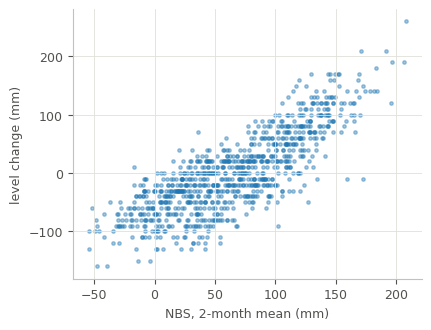

In [6]:
nbs2 = (df.nbs_mm + df.nbs_mm.shift()) / 2
ok = nbs2.notna()
slope, intercept = np.polyfit(nbs2[ok], df.dlevel_mm[ok], 1)
print(f'slope {slope:.2f}, intercept {intercept:.0f} mm/month, r = {np.corrcoef(nbs2[ok], df.dlevel_mm[ok])[0,1]:.2f}')
plt.figure(figsize=(4.5,3.5)); plt.scatter(nbs2, df.dlevel_mm, s=6, alpha=.4)
plt.xlabel('NBS, 2-month mean (mm)'); plt.ylabel('level change (mm)');

The slope is close to 1. The intercept (about −69 mm/month) is the water that leaves through the rivers on average, which we have no data for.

## 4. The seasonal cycle is a strong baseline

**Intuition.** The lake rises every spring (snowmelt) and falls every autumn (evaporation). A forecast that only knows the calendar already does well, so any model has to beat *this*, not just persistence.

In [7]:
clim = SeasonalClimatology().fit(df)
(clim.mean_change_ / 10).round(1).rename('average level change (cm)').to_frame().T

,1,2,3,4,5,6,7,8,9,10,11,12
average level change (cm),-3.7,-1.8,1.5,8.5,9.8,6.4,3.1,-1.7,-5.1,-6.5,-5.5,-4.3


## 5. The water-balance model

**Intuition.** A regression shaped like the bathtub: level change = supply terms (this month and last) + a monthly constant + a term that lets outflow grow when the lake is high. Coefficients near +1 for P and R and −1 for E would mean a perfect water budget.

In [8]:
wb = WaterBalance().fit(df)
c = wb.coefficients()
print('P  (lag0 + lag1):', round(c['precip_mm_lag0'] + c['precip_mm_lag1'], 2))
print('E  (lag0 + lag1):', round(c['evap_mm_lag0'] + c['evap_mm_lag1'], 2))
print('R  (lag0 + lag1):', round(c['runoff_mm_lag0'] + c['runoff_mm_lag1'], 2))
print('level (mm per m):', round(c['level_m'], 1))

P  (lag0 + lag1): 0.88
E  (lag0 + lag1): -0.81
R  (lag0 + lag1): 1.83
level (mm per m): -23.0


P and E are near ±1 and the level term is negative, as expected. Runoff is well above 1, which means it is standing in for something unmeasured (see the report's limitations).

**To forecast**, we do not know next month's weather. The model fills it in with the seasonal average plus a fading share of the latest anomaly. How fast does an anomaly fade?

In [9]:
dict(zip(['precip', 'evap', 'runoff'], wb.phi_.round(2).tolist()))

{'precip': 0.02, 'evap': 0.26, 'runoff': 0.45}

Precipitation anomalies do not carry over at all (≈0); runoff carries over about half. This is why skill fades quickly with horizon.

## 6. Rolling-origin backtest

**Intuition.** To test honestly, a model must never see the year it is tested on. For each year from 1980 on, we train on everything before it, forecast that year, then step forward. `backtest` does this for every model and every forecast is saved to `data/processed/predictions.csv`.

This cell takes about 5 minutes.

In [10]:
preds = backtest(df)
preds.to_csv(PROCESSED / "predictions.csv", index=False, float_format="%.4f")

table = rmse_table(preds)
table.to_csv(PROCESSED / "rmse_by_horizon.csv", float_format="%.3f")
years = preds["target"].dt.year
print(f"\nRMSE (cm) by horizon, test years {years.min()}-{years.max()}, "
      f"{preds['target'].nunique()} target months")
table.round(2)

/var/folders/hf/5tcdws1562jf0l3_2ctljpr80000gn/T/ipykernel_16969/3102517003.py:61: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cum += float(row @ self.coef_)


/var/folders/hf/5tcdws1562jf0l3_2ctljpr80000gn/T/ipykernel_16969/3102517003.py:61: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cum += float(row @ self.coef_)


/var/folders/hf/5tcdws1562jf0l3_2ctljpr80000gn/T/ipykernel_16969/3102517003.py:61: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cum += float(row @ self.coef_)


/var/folders/hf/5tcdws1562jf0l3_2ctljpr80000gn/T/ipykernel_16969/3102517003.py:61: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cum += float(row @ self.coef_)


/var/folders/hf/5tcdws1562jf0l3_2ctljpr80000gn/T/ipykernel_16969/3102517003.py:61: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cum += float(row @ self.coef_)


...

/var/folders/hf/5tcdws1562jf0l3_2ctljpr80000gn/T/ipykernel_16969/3102517003.py:61: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cum += float(row @ self.coef_)


/var/folders/hf/5tcdws1562jf0l3_2ctljpr80000gn/T/ipykernel_16969/3102517003.py:61: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cum += float(row @ self.coef_)


/var/folders/hf/5tcdws1562jf0l3_2ctljpr80000gn/T/ipykernel_16969/3102517003.py:61: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cum += float(row @ self.coef_)
/var/folders/hf/5tcdws1562jf0l3_2ctljpr80000gn/T/ipykernel_16969/3102517003.py:61: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cum += float(row @ self.coef_)
/var/folders/hf/5tcdws1562jf0l3_2ctljpr80000gn/T/ipykernel_16969/3102517003.py:61: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  cum += float(row @ s

  tested 2023
RMSE (cm) by horizon, test years 1980-2023, 528 target months


horizon,1,2,3,4,5,6
model,,,,,,
Persistence,6.73,12.37,17.06,20.73,23.30,24.81
Seasonal climatology,4.14,7.06,9.48,11.63,13.53,15.27
Water balance,3.22,6.33,8.82,11.03,12.96,14.66
Gradient boosting,3.32,6.52,9.13,11.42,13.51,15.39
Hybrid (WB + GB residual),3.27,6.36,8.97,11.18,12.98,14.59
"WB, perfect forcing (upper bound)",2.39,3.77,5.08,6.29,7.43,8.49


Reload the saved forecasts, so everything below uses exactly what is on disk:

In [11]:
preds = pd.read_csv(PROCESSED / "predictions.csv")
for col in ("target", "origin"):
    preds[col] = pd.PeriodIndex(preds[col], freq="M")
rmse_table(preds).round(2)

horizon,1,2,3,4,5,6
model,,,,,,
Persistence,6.73,12.37,17.06,20.73,23.30,24.81
Seasonal climatology,4.14,7.06,9.48,11.63,13.53,15.27
Water balance,3.22,6.33,8.82,11.03,12.96,14.66
Gradient boosting,3.32,6.52,9.13,11.42,13.51,15.39
Hybrid (WB + GB residual),3.27,6.36,8.97,11.18,12.98,14.59
"WB, perfect forcing (upper bound)",2.39,3.77,5.08,6.29,7.43,8.49


**Reading the table (RMSE in cm, lower is better).** Everything beats persistence. Water balance is best or tied at every horizon; gradient boosting is slightly worse. Is that gap real? Resample whole test years and look at the 95% interval of the difference:

In [12]:
bootstrap_rmse_diff(preds, 'Gradient boosting', 'Water balance').round(2)

,diff_cm,ci_low,ci_high
horizon,,,
1,0.10,-0.02,0.23
2,0.19,-0.06,0.45
3,0.32,-0.07,0.70
4,0.39,-0.13,0.93
5,0.54,-0.14,1.23
6,0.72,-0.16,1.62


Every interval includes zero: gradient boosting is not *significantly* worse, but there is no sign it is better.

The row `WB, perfect forcing` is not a forecast. It uses the weather that actually happened, and shows how much error is simply not knowing the future.

The same comparison for the other pairs of models:

In [13]:
for a, b in [("Hybrid (WB + GB residual)", "Water balance"),
             ("Gradient boosting", "Seasonal climatology"),
             ("Water balance", "Seasonal climatology")]:
    print(f"\nRMSE({a}) - RMSE({b}), cm; negative = first is better")
    print(bootstrap_rmse_diff(preds, a, b).round(2).to_string())


RMSE(Hybrid (WB + GB residual)) - RMSE(Water balance), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1           0.05   -0.03     0.13
2           0.03   -0.15     0.20
3           0.15   -0.16     0.47
4           0.15   -0.31     0.63
5           0.02   -0.55     0.61
6          -0.08   -0.77     0.65

RMSE(Gradient boosting) - RMSE(Seasonal climatology), cm; negative = first is better


         diff_cm  ci_low  ci_high
horizon                          
1          -0.81   -1.04    -0.58
2          -0.54   -0.96    -0.13
3          -0.35   -0.94     0.22
4          -0.21   -0.95     0.49
5          -0.02   -0.85     0.83
6           0.11   -1.01     1.20

RMSE(Water balance) - RMSE(Seasonal climatology), cm; negative = first is better
         diff_cm  ci_low  ci_high
horizon                          
1          -0.92   -1.12    -0.70
2          -0.73   -1.17    -0.28
3          -0.67   -1.26    -0.08
4          -0.60   -1.41     0.20
5          -0.56   -1.59     0.48
6          -0.61   -1.99     0.65


## 7. Figures

Each call writes one report figure to `figures/` and the cell then shows it.

**Figure 1.** The data: the level record, and how each supply term varies through the year.

wrote figures/fig1_data_overview.png


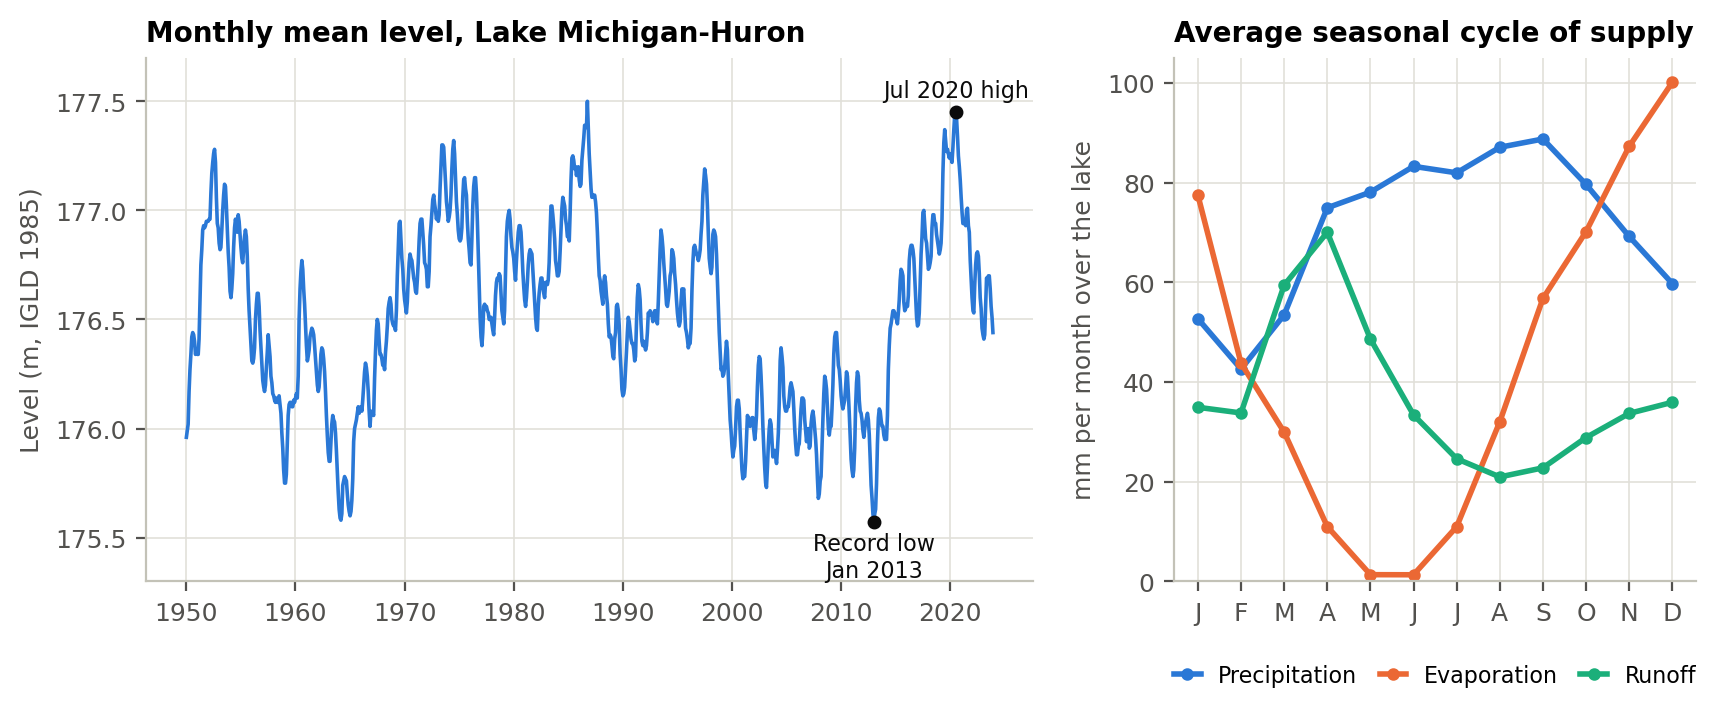

In [14]:
FIGURES.mkdir(exist_ok=True)
fig1_data(df)
display(Image(str(FIGURES / "fig1_data_overview.png"), width=800))

**Figure 2.** The bathtub check from section 3, as a report figure.

wrote figures/fig2_water_balance_check.png
  water-balance scatter: {'r': 0.811, 'slope': 1.069, 'intercept': -68.634}


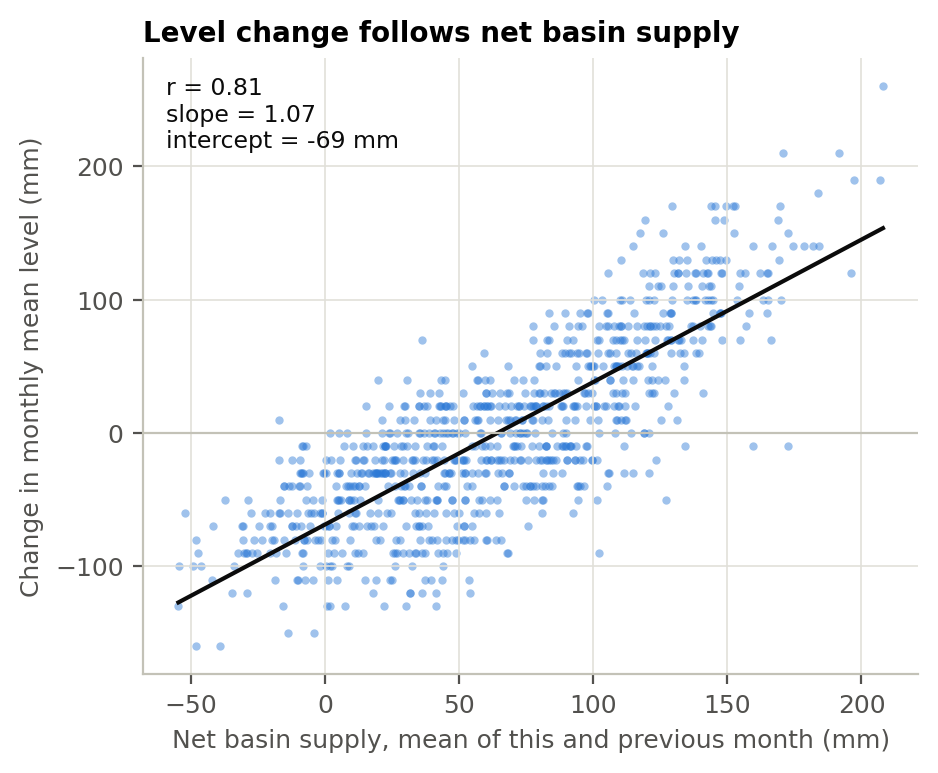

In [15]:
print("  water-balance scatter:", {k: round(float(v), 3) for k, v in fig2_water_balance(df).items()})
display(Image(str(FIGURES / "fig2_water_balance_check.png"), width=450))

**Figure 3.** Error by horizon for every model, and how much each improves on the seasonal baseline.

wrote figures/fig3_rmse_by_horizon.png


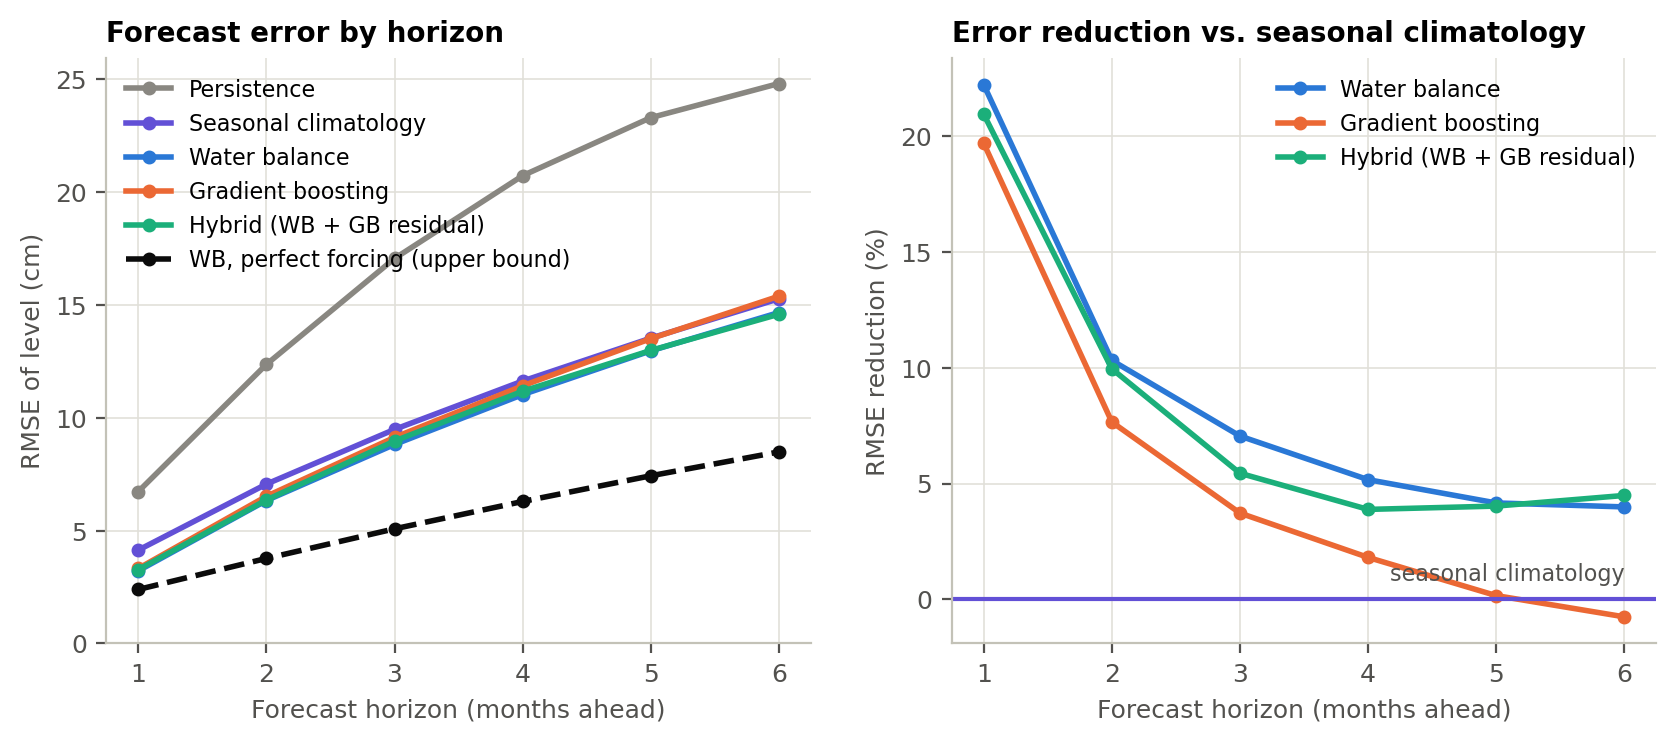

In [16]:
fig3_rmse(preds)
display(Image(str(FIGURES / "fig3_rmse_by_horizon.png"), width=800))

**Figure 4.** Which inputs the gradient-boosting model actually uses. Shuffle one
group of inputs and see how much the error grows; a big increase means the model
depended on it.

                              1      3     6
Accumulated NBS (3-12 mo)  0.04  -0.16 -0.08
Current level              0.10   0.39  1.10
Evaporation                0.93   0.37  8.84
Precipitation              0.60   0.52  0.05
Recent level change        0.77   0.90  2.00
Runoff                     1.55   0.74  1.11
Season (month)             1.18  10.48  1.73
wrote figures/fig4_feature_importance.png


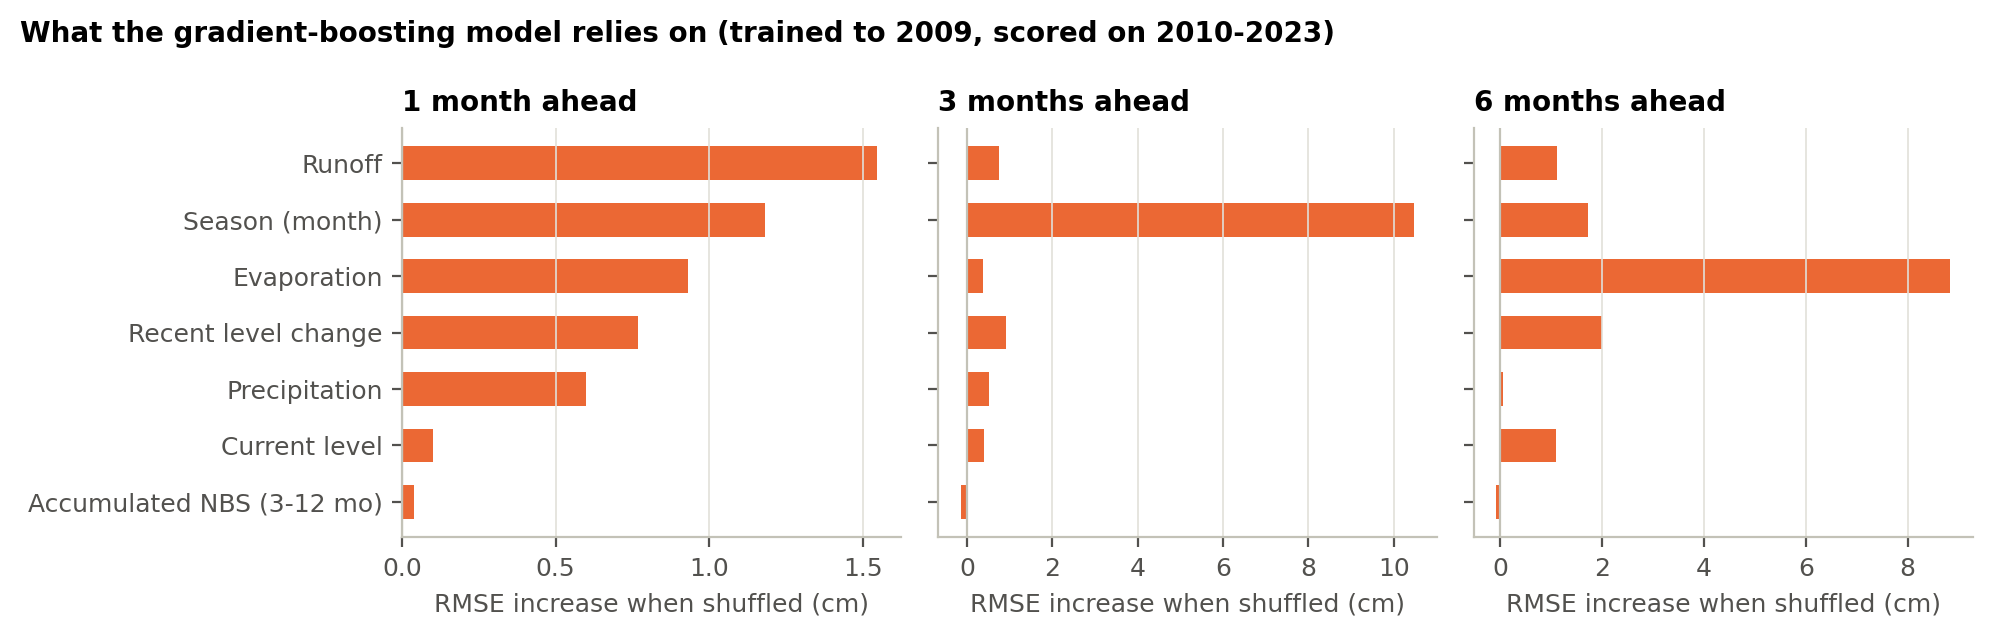

In [17]:
importance = permutation_importance(df)  # ~10 s
importance.to_csv(PROCESSED / "importance.csv", float_format="%.3f")
print(importance.round(2).to_string())
fig4_importance(importance)
display(Image(str(FIGURES / "fig4_feature_importance.png"), width=800))

**Figure 5.** The 2013 low to 2020 high: what the 6-month forecasts did, and which supply term drove the rise.

wrote figures/fig5_case_study_2013_2020.png
  case study: {'level_rise_m': 1.88, 'cum_precip_cm': 79.95, 'cum_minus_evap_cm': -59.49, 'cum_runoff_cm': 82.73}


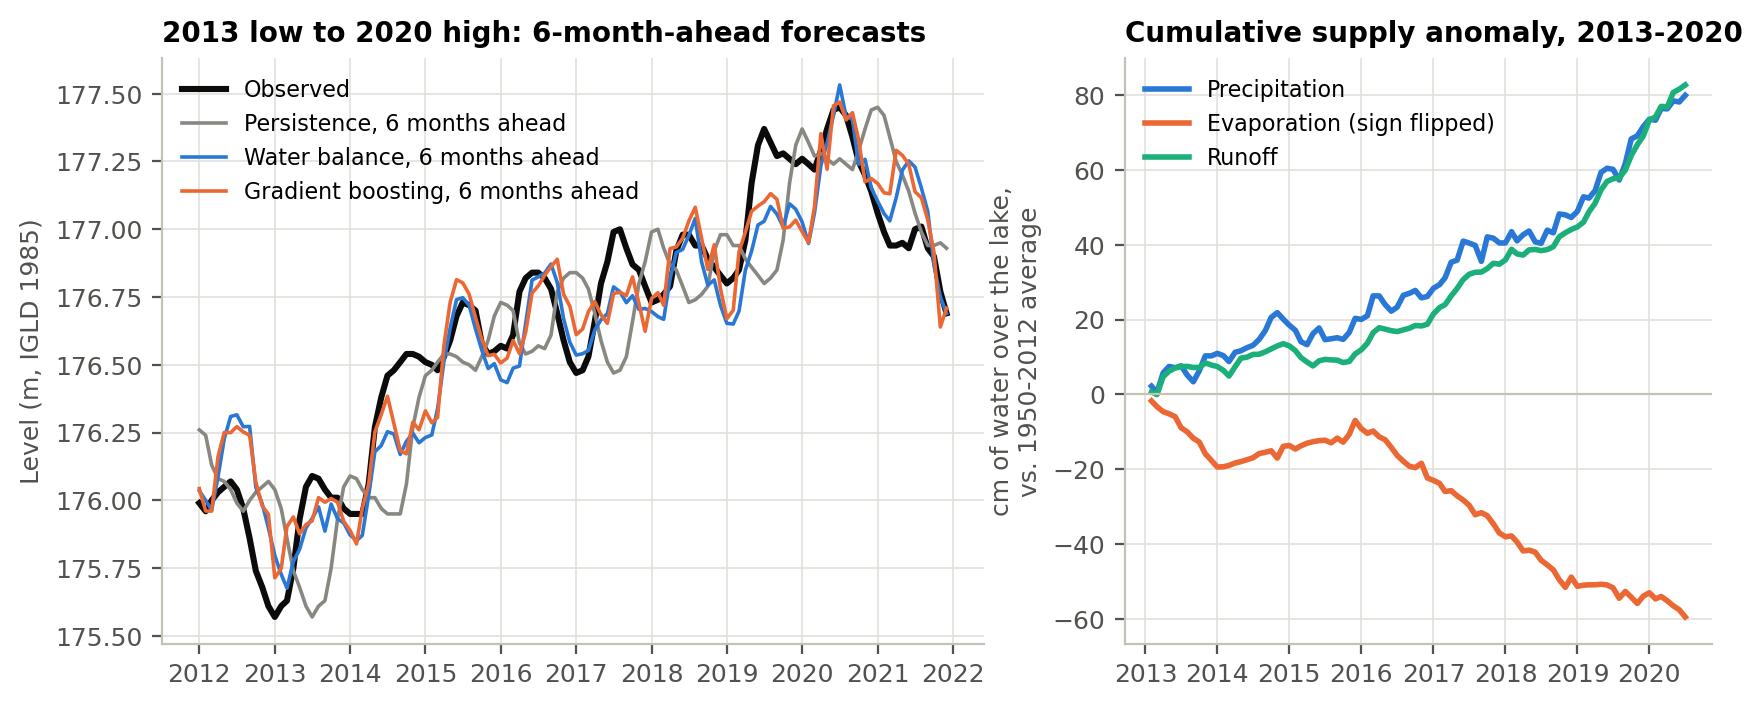

In [18]:
print("  case study:", {k: round(float(v), 2) for k, v in fig5_case_study(df, preds).items()})
display(Image(str(FIGURES / "fig5_case_study_2013_2020.png"), width=800))

## 8. Numbers quoted in the report

The water-balance coefficients fitted on the full record (saved to
`data/processed/wb_coefficients.csv`), and the RMSE table restricted to the
2013–2020 case-study years.

In [19]:
wb = WaterBalance().fit(df)
wb.coefficients().to_csv(PROCESSED / "wb_coefficients.csv", header=["coef"], float_format="%.4f")
print(wb.coefficients().round(3).to_string())
print("  AR(1) of P/E/R anomalies:", dict(zip(COMPONENTS, wb.phi_.round(2).tolist())))

month_1           -82.839
month_2           -78.546
month_3           -93.645
month_4           -78.085
month_5           -67.042
month_6           -74.861
month_7           -84.620
month_8          -110.054
month_9          -128.804
month_10         -135.559
month_11         -116.113
month_12          -89.627
precip_mm_lag0      0.354
evap_mm_lag0       -0.433
runoff_mm_lag0      1.224
precip_mm_lag1      0.531
evap_mm_lag1       -0.374
runoff_mm_lag1      0.607
level_m           -22.985
  AR(1) of P/E/R anomalies: {'precip_mm': 0.02, 'evap_mm': 0.26, 'runoff_mm': 0.45}


In [20]:
case = preds[(preds["target"] >= "2013-01") & (preds["target"] <= "2020-12")]
print("RMSE (cm), targets 2013-2020 only")
print(rmse_table(case).round(2).to_string())

RMSE (cm), targets 2013-2020 only
horizon                               1      2      3      4      5      6
model                                                                     
Persistence                        7.00  12.94  17.88  21.84  24.75  26.65
Seasonal climatology               4.04   6.99   9.41  11.76  14.01  16.14
Water balance                      2.89   5.96   8.33  10.54  12.86  15.02
Gradient boosting                  3.03   6.17   8.40  10.67  12.75  14.58
Hybrid (WB + GB residual)          3.03   6.14   8.30  10.52  12.56  14.67
WB, perfect forcing (upper bound)  2.38   3.88   5.20   6.45   7.66   8.85
